In [18]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()

In [19]:
path = '/content/drive/MyDrive/students(1).csv'
df = pd.read_csv(path, encoding = 'utf-8-sig')

display(df.head())

print('Размер датасета:')
print(df.shape)

print('\nНазвание столбцов')
print(df.columns.tolist())

print('\nТипы данных')
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isna().sum())

,ProcessInstanceId,EventId,EventIndex,ActivityId,ActivityName,EventType,Timestamp,TaskId,UserId,Role,Result,Amount,TemplateVersion
0,2fcc6cf4-603b-5153-b1f6-80db32e6b362,fb9972bf-8937-590f-ad7b-6c81d47eb3b6,1,6f98ac87-3a96-5225-b192-cbdcc3b0a72e,Регистрация заявки,process_started,2026-01-12T13:33:14+03:00,NaN,NaN,system,NaN,40381.01,1
1,2fcc6cf4-603b-5153-b1f6-80db32e6b362,56de6be4-8e08-551a-bc78-184e5ca68ddc,2,39abc4fb-3090-51ae-85d6-1b8972335c53,Первичная проверка,task_completed,2026-01-12T13:55:16+03:00,29f48ac9-2e5c-5133-aa1c-f048626b1aa9,651584b7-c62e-5bd5-92e7-5779eb0da396,specialist,accept,40381.01,1
2,2fcc6cf4-603b-5153-b1f6-80db32e6b362,4c83b51b-2291-5fd7-909d-b69a9761b325,3,09aa2e4c-5623-5d81-ae6a-9b037ace0dbf,Согласование руководителем,task_completed,2026-01-12T16:28:46+03:00,6acb7492-d5ff-5854-9a27-697448f68b59,56b425e1-c05d-5c5f-a859-a3d9800efd1d,manager,accept,40381.01,1
3,011ca340-ea26-5cbf-b311-3205d3c0510b,7183b24e-8cfd-5e8f-8a0c-3dc9c11bf96d,1,6f98ac87-3a96-5225-b192-cbdcc3b0a72e,Регистрация заявки,process_started,2026-01-13T09:00:00+03:00,NaN,NaN,system,NaN,91685.87,1
4,51641f06-ccaa-55aa-b5af-ac8dc5b3fa87,1e0b10ee-d7d4-5ab3-9b10-a7c440e4ca8e,1,6f98ac87-3a96-5225-b192-cbdcc3b0a72e,Регистрация заявки,process_started,2026-01-13T09:00:00+03:00,NaN,NaN,system,NaN,127410.42,1


Размер датасета:
(6508, 13)

Название столбцов
['ProcessInstanceId', 'EventId', 'EventIndex', 'ActivityId', 'ActivityName', 'EventType', 'Timestamp', 'TaskId', 'UserId', 'Role', 'Result', 'Amount', 'TemplateVersion']

Типы данных
ProcessInstanceId     object
EventId               object
EventIndex             int64
ActivityId            object
ActivityName          object
EventType             object
Timestamp             object
TaskId                object
UserId                object
Role                  object
Result                object
Amount               float64
TemplateVersion        int64
dtype: object

Количество пропусков:
ProcessInstanceId       0
EventId                 0
EventIndex              0
ActivityId              0
ActivityName            0
EventType               0
Timestamp               0
TaskId               2000
UserId               2000
Role                    0
Result               1000
Amount                  0
TemplateVersion         0
dtype: int64


In [20]:
print('Типы событий')
print(df['EventType'].value_counts())

print("\nНазвания действий")
print(df['ActivityName'].value_counts())

Типы событий
EventType
task_completed       4508
process_started      1000
process_completed    1000
Name: count, dtype: int64

Названия действий
ActivityName
Первичная проверка             1174
Согласование руководителем     1129
Регистрация заявки             1000
Проверка бюджета                911
Исполнение закупки              911
Заявка выполнена                911
Дополнительное согласование     209
Доработка заявки                174
Заявка отклонена                 63
Заявка отменена                  26
Name: count, dtype: int64


In [21]:
print('Уникальных заявок')
print(df['ProcessInstanceId'].nunique())

print('\nКоличество событий на одну заявку')
print(df.groupby("ProcessInstanceId").size().describe())

Уникальных заявок
1000

Количество событий на одну заявку
count    1000.000000
mean        6.508000
std         1.597024
min         3.000000
25%         6.000000
50%         6.000000
75%         7.000000
max        12.000000
dtype: float64


In [22]:
df_sorted = df.sort_values(
    by=["ProcessInstanceId", "EventIndex"]
)

first_id = df_sorted["ProcessInstanceId"].iloc[0]

first_case = df_sorted[
    df_sorted["ProcessInstanceId"] == first_id
]

display(
    first_case[
        ["EventIndex", "ActivityName", "EventType", "Result"]
    ]
)

,EventIndex,ActivityName,EventType,Result
4211,1,Регистрация заявки,process_started,NaN
4223,2,Первичная проверка,task_completed,accept
4235,3,Согласование руководителем,task_completed,return
4260,4,Доработка заявки,task_completed,accept
4268,5,Первичная проверка,task_completed,accept
4291,6,Согласование руководителем,task_completed,return
4298,7,Доработка заявки,task_completed,accept
4299,8,Первичная проверка,task_completed,accept
4315,9,Согласование руководителем,task_completed,accept
4318,10,Проверка бюджета,task_completed,accept


In [23]:
routes = (
    df_sorted
    .groupby("ProcessInstanceId")["ActivityName"]
    .agg(" > ".join)
)

print("Количество восстановленных маршрутов:", len(routes))

display(routes.head())

Количество восстановленных маршрутов: 1000


,ActivityName
ProcessInstanceId,
009608ae-1567-584a-b67a-c7ec60ec587d,Регистрация заявки > Первичная проверка > Согл...
00e3854b-efb6-59c7-ac6a-c85643843db1,Регистрация заявки > Первичная проверка > Согл...
00f3e3a0-9d7d-5eac-98a9-b605b6893e61,Регистрация заявки > Первичная проверка > Согл...
01128d40-0f1e-52f4-b941-344c39ba7b8d,Регистрация заявки > Первичная проверка > Согл...
011698a3-7d54-5dc3-8afb-85b902834992,Регистрация заявки > Первичная проверка > Согл...


In [24]:
variant_counts = routes.value_counts()

print("Количество уникальных маршрутов:")
print(len(variant_counts))

print("\nСамые распространённые маршруты:")
for route, count in variant_counts.head(10).items():
    print(f"\nКоличество заявок: {count}")
    print(f"Маршрут: {route}")

Количество уникальных маршрутов:
8

Самые распространённые маршруты:

Количество заявок: 567
Маршрут: Регистрация заявки > Первичная проверка > Согласование руководителем > Проверка бюджета > Исполнение закупки > Заявка выполнена

Количество заявок: 188
Маршрут: Регистрация заявки > Первичная проверка > Согласование руководителем > Проверка бюджета > Дополнительное согласование > Исполнение закупки > Заявка выполнена

Количество заявок: 117
Маршрут: Регистрация заявки > Первичная проверка > Согласование руководителем > Доработка заявки > Первичная проверка > Согласование руководителем > Проверка бюджета > Исполнение закупки > Заявка выполнена

Количество заявок: 45
Маршрут: Регистрация заявки > Первичная проверка > Заявка отклонена

Количество заявок: 26
Маршрут: Регистрация заявки > Первичная проверка > Согласование руководителем > Заявка отменена

Количество заявок: 21
Маршрут: Регистрация заявки > Первичная проверка > Согласование руководителем > Доработка заявки > Первичная проверк

In [25]:
activity_cases = (
    df.groupby("ActivityName")["ProcessInstanceId"]
    .nunique()
    .sort_values(ascending=False)
)

activity_share = activity_cases / df["ProcessInstanceId"].nunique()

activity_stats = pd.DataFrame({
    "NumberOfCases": activity_cases,
    "Share": activity_share
})

display(activity_stats)

,NumberOfCases,Share
ActivityName,,
Первичная проверка,1000,1.000
Регистрация заявки,1000,1.000
Согласование руководителем,955,0.955
Проверка бюджета,911,0.911
Исполнение закупки,911,0.911
Заявка выполнена,911,0.911
Дополнительное согласование,209,0.209
Доработка заявки,156,0.156
Заявка отклонена,63,0.063


In [26]:
df_sorted = df_sorted.copy()

df_sorted["NextActivity"] = (
    df_sorted.groupby("ProcessInstanceId")["ActivityName"].shift(-1)
)

transitions = (
    df_sorted.dropna(subset=["NextActivity"])
    .groupby(["ActivityName", "NextActivity"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(transitions)

,ActivityName,NextActivity,Count
4,Первичная проверка,Согласование руководителем,1129
7,Регистрация заявки,Первичная проверка,1000
2,Исполнение закупки,Заявка выполнена,911
11,Согласование руководителем,Проверка бюджета,911
6,Проверка бюджета,Исполнение закупки,702
5,Проверка бюджета,Дополнительное согласование,209
0,Дополнительное согласование,Исполнение закупки,209
1,Доработка заявки,Первичная проверка,174
8,Согласование руководителем,Доработка заявки,174
3,Первичная проверка,Заявка отклонена,45


In [27]:
print("Всего переходов:", transitions["Count"].sum())

print("Ожидается:", len(df) - df["ProcessInstanceId"].nunique())

Всего переходов: 5508
Ожидается: 5508


In [28]:
variants_df = variant_counts.reset_index()
variants_df.columns = ["Route", "NumberOfCases"]

variants_df.insert(
    0,
    "Variant",
    ["V" + str(i) for i in range(1, len(variants_df) + 1)]
)

variants_df["Share"] = (
    variants_df["NumberOfCases"] / len(routes)
)

display(variants_df)

print("Всего заявок:", variants_df["NumberOfCases"].sum())
print("Сумма долей:", variants_df["Share"].sum())

,Variant,Route,NumberOfCases,Share
0,V1,Регистрация заявки > Первичная проверка > Согл...,567,0.567
1,V2,Регистрация заявки > Первичная проверка > Согл...,188,0.188
2,V3,Регистрация заявки > Первичная проверка > Согл...,117,0.117
3,V4,Регистрация заявки > Первичная проверка > Заяв...,45,0.045
4,V5,Регистрация заявки > Первичная проверка > Согл...,26,0.026
5,V6,Регистрация заявки > Первичная проверка > Согл...,21,0.021
6,V7,Регистрация заявки > Первичная проверка > Согл...,18,0.018
7,V8,Регистрация заявки > Первичная проверка > Согл...,18,0.018


Всего заявок: 1000
Сумма долей: 0.9999999999999999


In [29]:
import numpy as np

print(np.isclose(variants_df["Share"].sum(), 1.0))

True


In [30]:
# Сохраняем полные варианты
variants_df.to_csv(
    "variants.csv",
    index=False,
    encoding="utf-8-sig"
)

# Сохраняем уникальные переходы
transitions_export = transitions[
    ["ActivityName", "NextActivity"]
].rename(columns={
    "ActivityName": "SourceActivity",
    "NextActivity": "TargetActivity"
})

transitions_export.to_csv(
    "student_transitions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Файлы успешно созданы!")

Файлы успешно созданы!


In [32]:
G = nx.DiGraph()

for _, row in transitions.iterrows():
    source = row["ActivityName"]
    target = row["NextActivity"]
    count = int(row["Count"])

    G.add_edge(source, target, weight=count)

print("Количество узлов:", G.number_of_nodes())
print("Количество переходов:", G.number_of_edges())

Количество узлов: 10
Количество переходов: 12


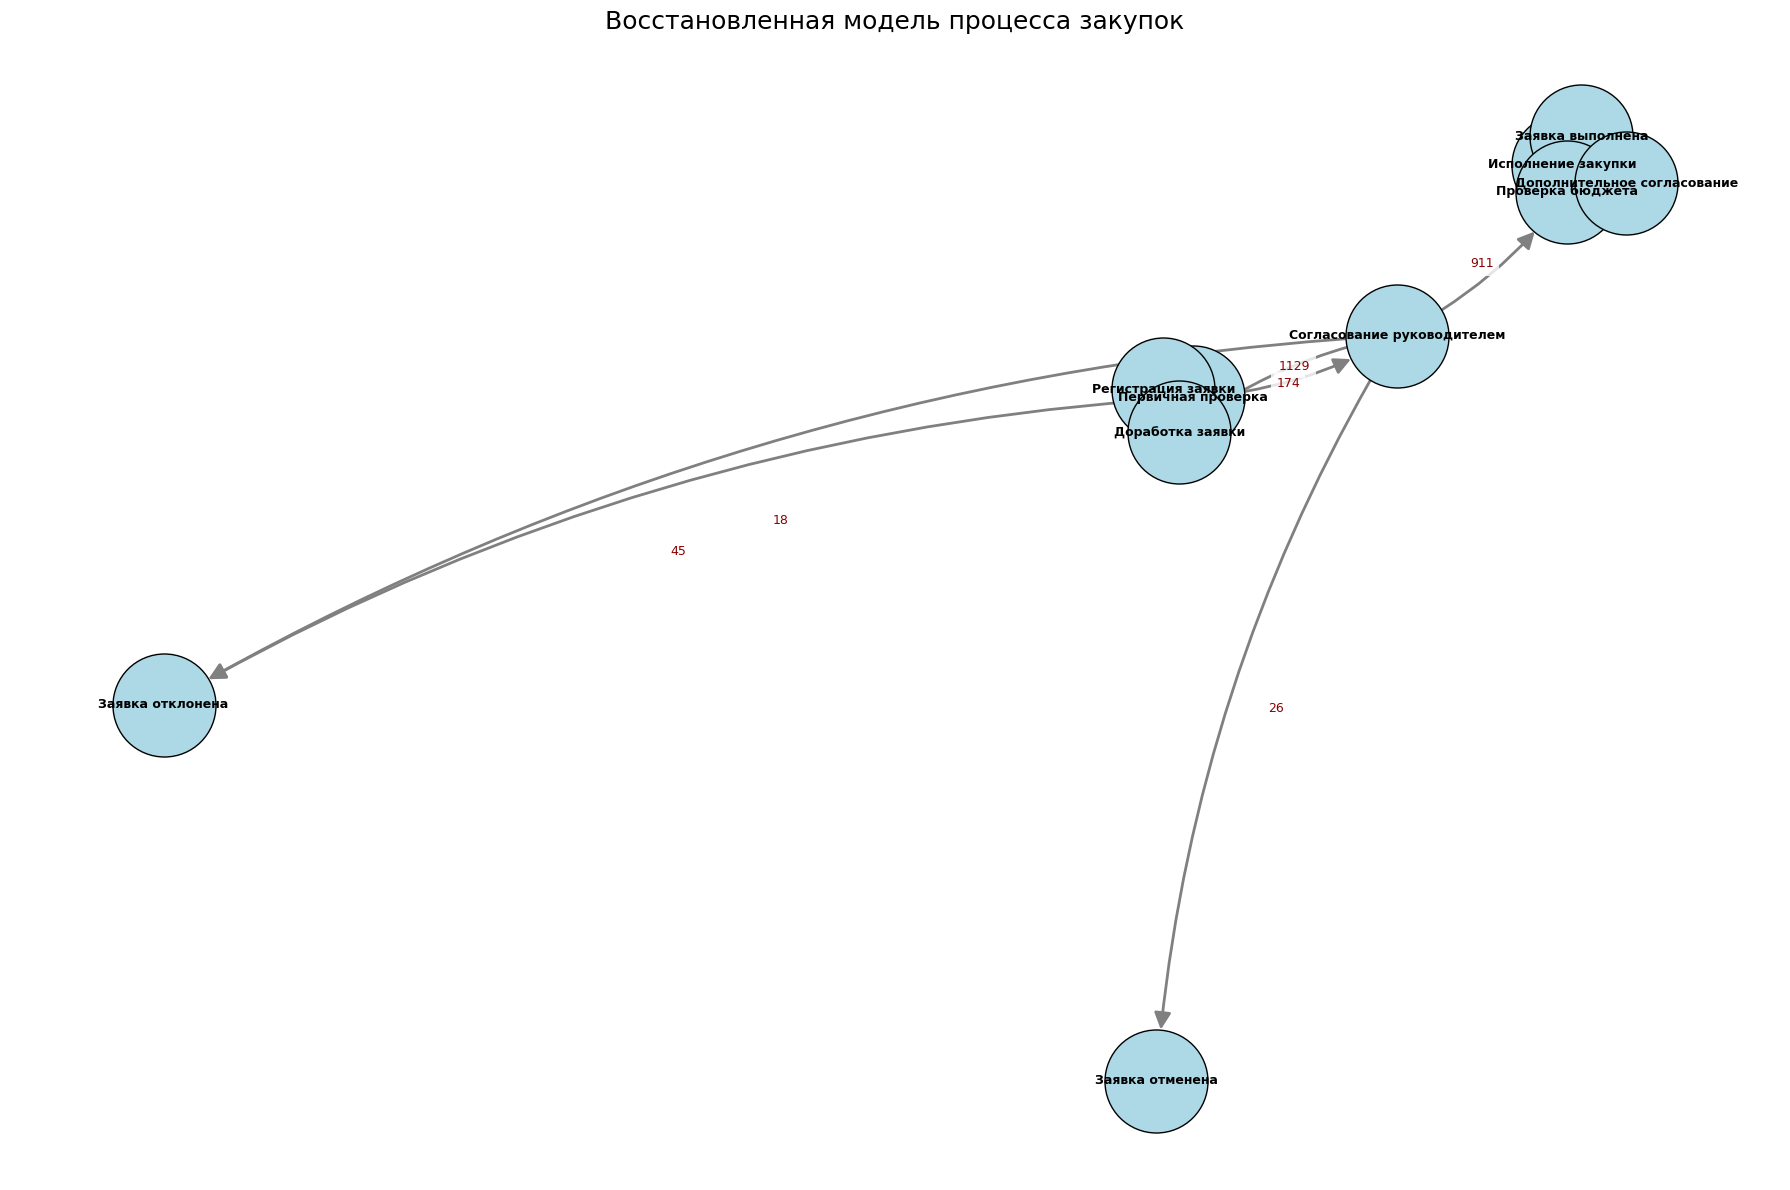

In [33]:
plt.figure(figsize=(18, 12))

pos = nx.spring_layout(
    G,
    seed=42,
    k=2.5,
    iterations=200
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=5500,
    node_color="lightblue",
    edgecolors="black"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9,
    font_weight="bold"
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=25,
    node_size=5500,
    width=2,
    edge_color="gray",
    connectionstyle="arc3,rad=0.12"
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9,
    font_color="darkred",
    rotate=False,
    bbox={
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.8
    }
)

plt.title("Восстановленная модель процесса закупок", fontsize=18)
plt.axis("off")
plt.tight_layout()
plt.show()

In [34]:
!pip -q install graphviz

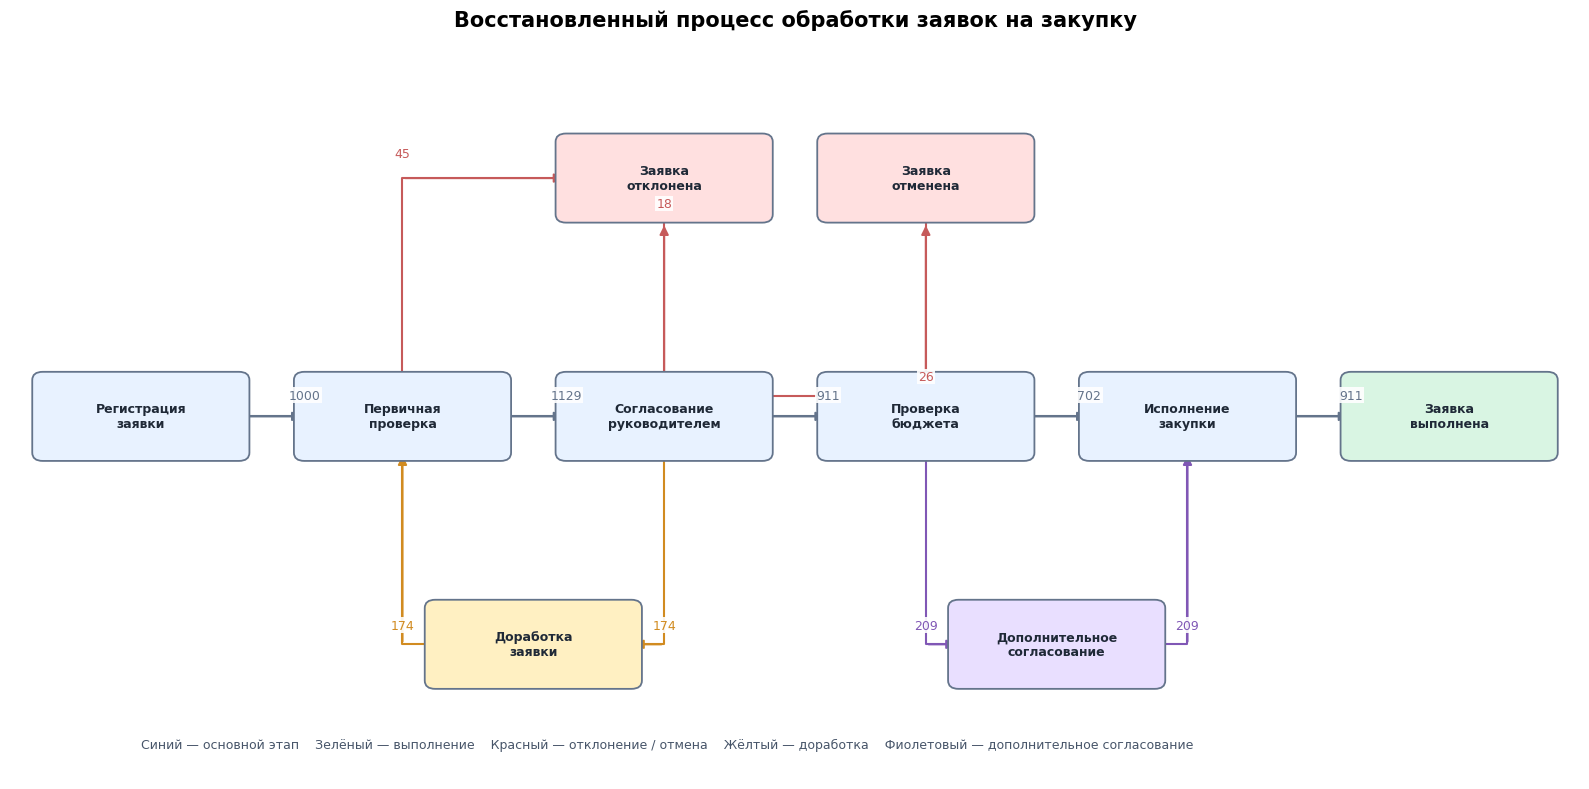

In [37]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import textwrap

# Настраиваем шрифт
plt.rcParams["font.family"] = "DejaVu Sans"

# Частоты переходов из нашего анализа
counts = {
    (row["ActivityName"], row["NextActivity"]): int(row["Count"])
    for _, row in transitions.iterrows()
}

# Короткие названия блоков
labels = {
    "Регистрация заявки": "Регистрация\nзаявки",
    "Первичная проверка": "Первичная\nпроверка",
    "Согласование руководителем": "Согласование\nруководителем",
    "Проверка бюджета": "Проверка\nбюджета",
    "Дополнительное согласование": "Дополнительное\nсогласование",
    "Исполнение закупки": "Исполнение\nзакупки",
    "Заявка выполнена": "Заявка\nвыполнена",
    "Заявка отклонена": "Заявка\nотклонена",
    "Заявка отменена": "Заявка\nотменена",
    "Доработка заявки": "Доработка\nзаявки"
}

# Позиции блоков
positions = {
    "Регистрация заявки": (0, 3),
    "Первичная проверка": (2, 3),
    "Согласование руководителем": (4, 3),
    "Проверка бюджета": (6, 3),
    "Исполнение закупки": (8, 3),
    "Заявка выполнена": (10, 3),

    "Заявка отклонена": (4, 5.3),
    "Заявка отменена": (6, 5.3),

    "Доработка заявки": (3, 0.8),
    "Дополнительное согласование": (7, 0.8)
}

fig, ax = plt.subplots(figsize=(16, 8))

ax.set_xlim(-1, 11)
ax.set_ylim(-0.5, 6.5)
ax.axis("off")

# Цвета
MAIN = "#E8F2FF"
SUCCESS = "#D9F5E3"
DANGER = "#FFE0E0"
RETURN = "#FFF0C2"
OPTIONAL = "#E9DFFF"

# Рисуем блоки
for activity, (x, y) in positions.items():

    if activity == "Заявка выполнена":
        color = SUCCESS
    elif activity in ["Заявка отклонена", "Заявка отменена"]:
        color = DANGER
    elif activity == "Доработка заявки":
        color = RETURN
    elif activity == "Дополнительное согласование":
        color = OPTIONAL
    else:
        color = MAIN

    box = FancyBboxPatch(
        (x - 0.75, y - 0.35),
        1.5,
        0.7,
        boxstyle="round,pad=0.08",
        linewidth=1.3,
        edgecolor="#64748B",
        facecolor=color,
        zorder=3
    )

    ax.add_patch(box)

    ax.text(
        x, y,
        labels[activity],
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#1F2937",
        zorder=4
    )


# Функция рисования стрелок
def draw_arrow(source, target, points=None, color="#64748B",
               label_offset=(0, 0.15)):

    sx, sy = positions[source]
    tx, ty = positions[target]

    if points is None:
        points = [(sx, sy), (tx, ty)]

    # Рисуем линию по заданным точкам
    xs, ys = zip(*points)

    ax.plot(
        xs, ys,
        color=color,
        linewidth=1.5,
        zorder=1
    )

    # Стрелка на последнем участке
    arrow = FancyArrowPatch(
        points[-2],
        points[-1],
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=1.5,
        color=color,
        zorder=2
    )
    ax.add_patch(arrow)

    # Подписываем количество переходов
    count = counts.get((source, target))

    if count is not None:
        mid = points[len(points) // 2]

        ax.text(
            mid[0] + label_offset[0],
            mid[1] + label_offset[1],
            str(count),
            fontsize=9,
            ha="center",
            color=color,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.9,
                pad=1
            ),
            zorder=5
        )


# Основной маршрут
main_route = [
    "Регистрация заявки",
    "Первичная проверка",
    "Согласование руководителем",
    "Проверка бюджета",
    "Исполнение закупки",
    "Заявка выполнена"
]

for source, target in zip(main_route[:-1], main_route[1:]):
    sx, sy = positions[source]
    tx, ty = positions[target]

    draw_arrow(
        source,
        target,
        points=[(sx + 0.75, sy), (tx - 0.75, ty)],
        label_offset=(0, 0.17)
    )


# Отклонение после первичной проверки
draw_arrow(
    "Первичная проверка",
    "Заявка отклонена",
    points=[(2, 3.35), (2, 5.3), (3.25, 5.3)],
    color="#C65A5A",
    label_offset=(0, 0.2)
)

# Отклонение после согласования
draw_arrow(
    "Согласование руководителем",
    "Заявка отклонена",
    points=[(4, 3.35), (4, 4.87)],
    color="#C65A5A"
)

# Отмена заявки
draw_arrow(
    "Согласование руководителем",
    "Заявка отменена",
    points=[(4.75, 3.2), (6, 3.2), (6, 4.87)],
    color="#C65A5A"
)

# Возврат на доработку
draw_arrow(
    "Согласование руководителем",
    "Доработка заявки",
    points=[(4, 2.65), (4, 0.8), (3.75, 0.8)],
    color="#D18B20"
)

draw_arrow(
    "Доработка заявки",
    "Первичная проверка",
    points=[(2.25, 0.8), (2, 0.8), (2, 2.65)],
    color="#D18B20"
)

# Дополнительное согласование
draw_arrow(
    "Проверка бюджета",
    "Дополнительное согласование",
    points=[(6, 2.65), (6, 0.8), (6.25, 0.8)],
    color="#8057B5"
)

draw_arrow(
    "Дополнительное согласование",
    "Исполнение закупки",
    points=[(7.75, 0.8), (8, 0.8), (8, 2.65)],
    color="#8057B5"
)

# Заголовок
ax.set_title(
    "Восстановленный процесс обработки заявок на закупку",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Легенда
ax.text(
    0, -0.2,
    "Синий — основной этап    "
    "Зелёный — выполнение    "
    "Красный — отклонение / отмена    "
    "Жёлтый — доработка    "
    "Фиолетовый — дополнительное согласование",
    fontsize=9,
    color="#475569"
)

plt.tight_layout()

# Сохраняем результат
plt.savefig(
    "process_discovery.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [38]:
# Проверяем, что все реальные маршруты поддерживаются графом

def check_route(route, graph):
    activities = route.split(" > ")

    return all(
        graph.has_edge(a, b)
        for a, b in zip(activities[:-1], activities[1:])
    )


results = routes.apply(lambda route: check_route(route, G))

print("Всего заявок:", len(results))
print("Поддерживаются графом:", results.sum())
print("Не поддерживаются:", (~results).sum())

print("\nКоличество уникальных маршрутов:", len(variant_counts))
print("Все маршруты поддерживаются:", results.all())

Всего заявок: 1000
Поддерживаются графом: 1000
Не поддерживаются: 0

Количество уникальных маршрутов: 8
Все маршруты поддерживаются: True


In [39]:
from google.colab import files

variants_df.to_csv(
    "variants.csv",
    index=False,
    encoding="utf-8-sig"
)

transitions_export.to_csv(
    "student_transitions.csv",
    index=False,
    encoding="utf-8-sig"
)

files.download("variants.csv")
files.download("student_transitions.csv")
files.download("process_discovery.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>